In [1]:
import scanpy as sc
import pandas as pd


In [6]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_matrix.mtx').T

In [3]:
old_pd 

AnnData object with n_obs × n_vars = 9727 × 36601

In [7]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_features.tsv", header=None)[1]

In [ ]:
gene_names

In [8]:
cell_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855408_232028_barcodes.tsv", header=None)[0]

In [12]:
cell_names

0       AAACCCAAGACATATG-1
1       AAACCCAAGCGGACAT-1
2       AAACCCAAGCTACTAC-1
3       AAACCCACACGAAAGC-1
4       AAACCCAGTATTGGCT-1
               ...        
9722    TTTGTTGGTGTTACTG-1
9723    TTTGTTGTCAGCATTG-1
9724    TTTGTTGTCCCTTGTG-1
9725    TTTGTTGTCCGCAAAT-1
9726    TTTGTTGTCGGTCAGC-1
Name: 0, Length: 9727, dtype: object

In [13]:
lineage_barcodes = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855412_232028_lineage_barcodes.csv")
                                                                                                                                                        

In [14]:
lineage_barcodes.set_index("cellbarcode", inplace=True)

In [15]:
lineage_barcodes["lid"].unique().shape

(160,)

In [16]:
old_pd.obs_names = cell_names

In [17]:
old_pd.var_names = gene_names

In [18]:
old_pd.obs["barcode"] = old_pd.obs_names.map(lineage_barcodes["lid"])

In [19]:
adata_no_nan = old_pd[old_pd.obs["barcode"].notna()]

In [22]:

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)


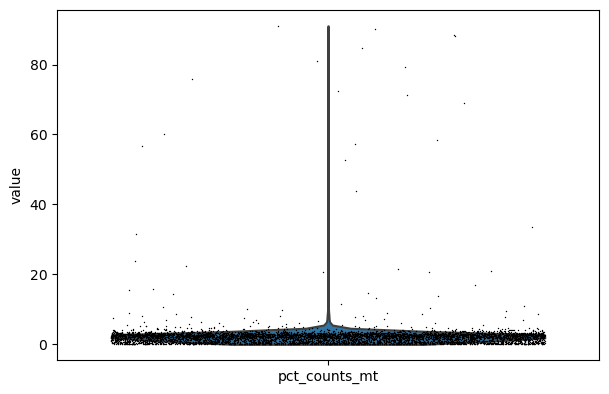

In [23]:
adata_no_nan.var_names_make_unique()
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [24]:

# Filter cells with >3.5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 3.5].copy()


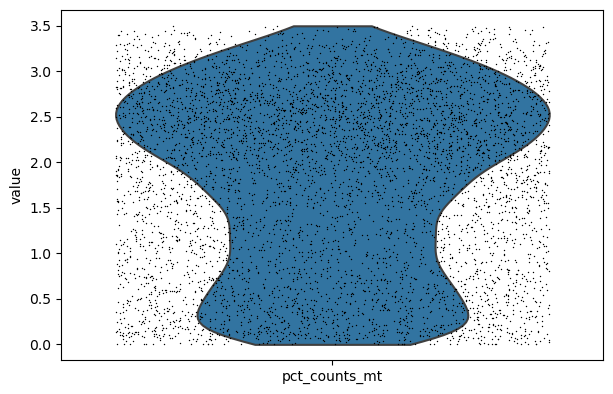

In [25]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [26]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [27]:
# preprocess
sc.pp.normalize_total(adata_no_nan, target_sum=1e4)
sc.pp.log1p(adata_no_nan)


In [28]:

adata_filtered = adata_no_nan#[:,  adata_no_nan.var.highly_variable]

In [29]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [30]:
df

,MIR1302-2HG,AL627309.1,AL627309.5,AL627309.4,AP006222.2,AL669831.2,LINC01409,FAM87B,LINC01128,LINC00115,...,MT-ND6,MT-CYB,AC011043.1,AC011043.2,AC011841.1,AC240274.1,AC004556.3,AC136352.3,AC007325.4,AC007325.2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.00000,...,1.057195,3.250118,0.560367,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.00000,...,1.002283,3.123626,0.000000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.583400,0.00000,...,1.046716,2.653384,0.000000,0.0,0.0,0.234313,0.00000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.00000,...,0.608417,3.088221,0.749856,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.00000,...,0.987721,2.243424,0.445777,0.0,0.0,0.445777,0.00000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5690,0.0,0.0,0.0,0.0,0.0,0.0,0.295908,0.0,0.000000,0.15886,...,0.790824,2.412177,0.523955,0.0,0.0,0.416418,0.15886,0.0,0.0,0.0
5691,0.0,0.0,0.0,0.0,0.0,0.0,0.412728,0.0,0.000000,0.00000,...,0.929326,3.198794,0.412728,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0
5692,0.0,0.0,0.0,0.0,0.0,0.0,0.757898,0.0,0.320582,0.00000,...,0.320582,2.911520,0.000000,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0
5693,0.0,0.0,0.0,0.0,0.0,0.0,0.497838,0.0,0.000000,0.00000,...,0.918439,1.852595,0.620692,0.0,0.0,0.194788,0.00000,0.0,0.0,0.0


In [31]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [32]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [33]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [34]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [35]:
df.drop(columns = ["barcode"], inplace = True)

In [36]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl")


